In [2]:
# Step 1: Import the libraries we will need

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms

from PIL import Image

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

Libraries imported successfully!
PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu


In [3]:
# Step 2: Check whether GPU is available

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device being used:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. The notebook is currently using CPU.")

Device being used: cpu
GPU is not available. The notebook is currently using CPU.


In [4]:
# Step 3: Find the MVTec AD dataset

import os

kaggle_input = "/kaggle/input"

print("Datasets available in /kaggle/input:")
print(os.listdir(kaggle_input))

Datasets available in /kaggle/input:
['datasets']


In [5]:
# Step 4: Inspect the contents of the Kaggle dataset folder

dataset_root = "/kaggle/input/datasets"

print("Contents of dataset folder:")
print(os.listdir(dataset_root))

Contents of dataset folder:
['ipythonx']


In [6]:
# Step 5: Inspect the ipythonx folder

ipythonx_path = "/kaggle/input/datasets/ipythonx"

print("Contents of ipythonx folder:")
print(os.listdir(ipythonx_path))

Contents of ipythonx folder:
['mvtec-ad']


In [7]:
# Step 6: Inspect the MVTec AD dataset

mvtec_path = "/kaggle/input/datasets/ipythonx/mvtec-ad"

print("Contents of MVTec AD dataset:")
print(os.listdir(mvtec_path))

Contents of MVTec AD dataset:
['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'license.txt', 'metal_nut', 'pill', 'readme.txt', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


In [8]:
# Step 7: Define the Bottle dataset path

bottle_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle"

print("Bottle dataset path:")
print(bottle_path)

print("\nContents of bottle folder:")
print(os.listdir(bottle_path))

Bottle dataset path:
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle

Contents of bottle folder:
['ground_truth', 'license.txt', 'readme.txt', 'test', 'train']


In [9]:
train_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train"

print("Contents of bottle/train:")

for item in os.listdir(train_path):
    print(item)

Contents of bottle/train:
good


In [10]:
test_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test"

print("Contents of bottle/test:")

for item in os.listdir(test_path):
    print(item)

Contents of bottle/test:
broken_large
broken_small
contamination
good


In [11]:
ground_truth_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth"

print("Contents of bottle/ground_truth:")

for item in os.listdir(ground_truth_path):
    print(item)

Contents of bottle/ground_truth:
broken_large
broken_small
contamination


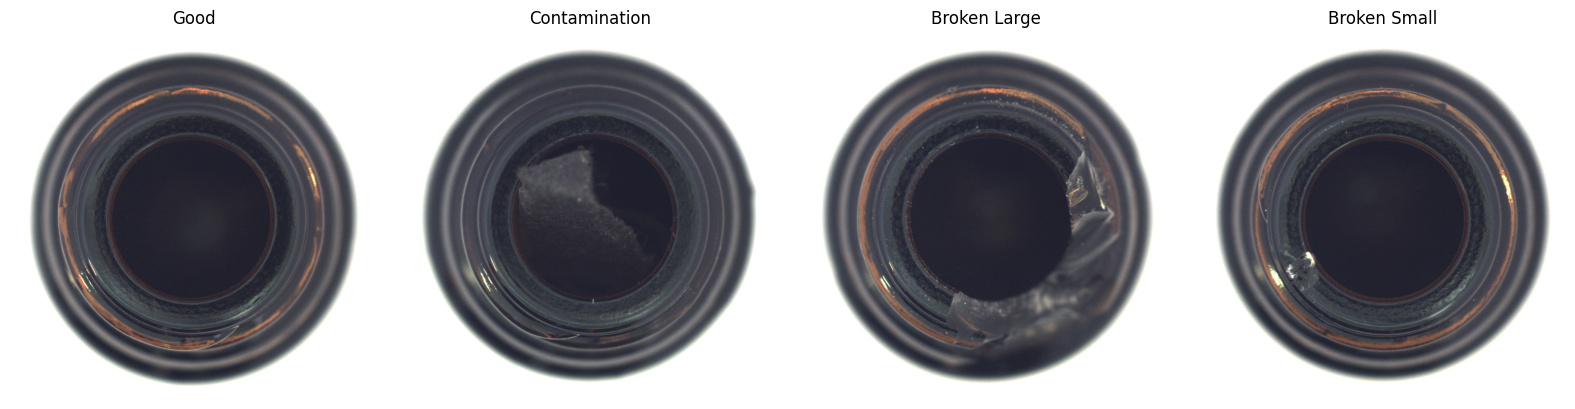

In [12]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Paths
good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/good"
contamination_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/contamination"
broken_large_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large"
broken_small_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_small"

# Get one image from each category
good_image = os.path.join(good_path, os.listdir(good_path)[0])
contamination_image = os.path.join(contamination_path, os.listdir(contamination_path)[0])
broken_large_image = os.path.join(broken_large_path, os.listdir(broken_large_path)[0])
broken_small_image = os.path.join(broken_small_path, os.listdir(broken_small_path)[0])

# Display images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    good_image,
    contamination_image,
    broken_large_image,
    broken_small_image
]

titles = [
    "Good",
    "Contamination",
    "Broken Large",
    "Broken Small"
]

for ax, image_path, title in zip(axes, images, titles):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Define the test dataset path
test_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test"

# Count images in each test category
categories = ["good", "contamination", "broken_large", "broken_small"]

for category in categories:
    category_path = os.path.join(test_path, category)
    
    image_files = [
        file for file in os.listdir(category_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    
    print(f"{category}: {len(image_files)} images")

good: 20 images
contamination: 21 images
broken_large: 20 images
broken_small: 22 images


In [14]:
# Define the training dataset path
train_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train"

good_train_path = os.path.join(train_path, "good")

train_images = [
    file for file in os.listdir(good_train_path)
    if file.lower().endswith((".png", ".jpg", ".jpeg"))
]

print(f"Training images (good): {len(train_images)}")

Training images (good): 209


In [15]:
# Step 8: Check the Bottle dataset structure and image counts

train_path = os.path.join(bottle_path, "train")
test_path = os.path.join(bottle_path, "test")
ground_truth_path = os.path.join(bottle_path, "ground_truth")

print("Training categories:", os.listdir(train_path))
print("Test categories:", os.listdir(test_path))
print("Ground-truth categories:", os.listdir(ground_truth_path))

# Count training images
train_good_path = os.path.join(train_path, "good")
train_images = [
    f for f in os.listdir(train_good_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("\nNumber of normal training images:", len(train_images))

# Count test images for each category
print("\nTest image counts:")

for category in sorted(os.listdir(test_path)):
    category_path = os.path.join(test_path, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        print(f"{category}: {len(images)}")

Training categories: ['good']
Test categories: ['broken_large', 'broken_small', 'contamination', 'good']
Ground-truth categories: ['broken_large', 'broken_small', 'contamination']

Number of normal training images: 209

Test image counts:
broken_large: 20
broken_small: 22
contamination: 21
good: 20


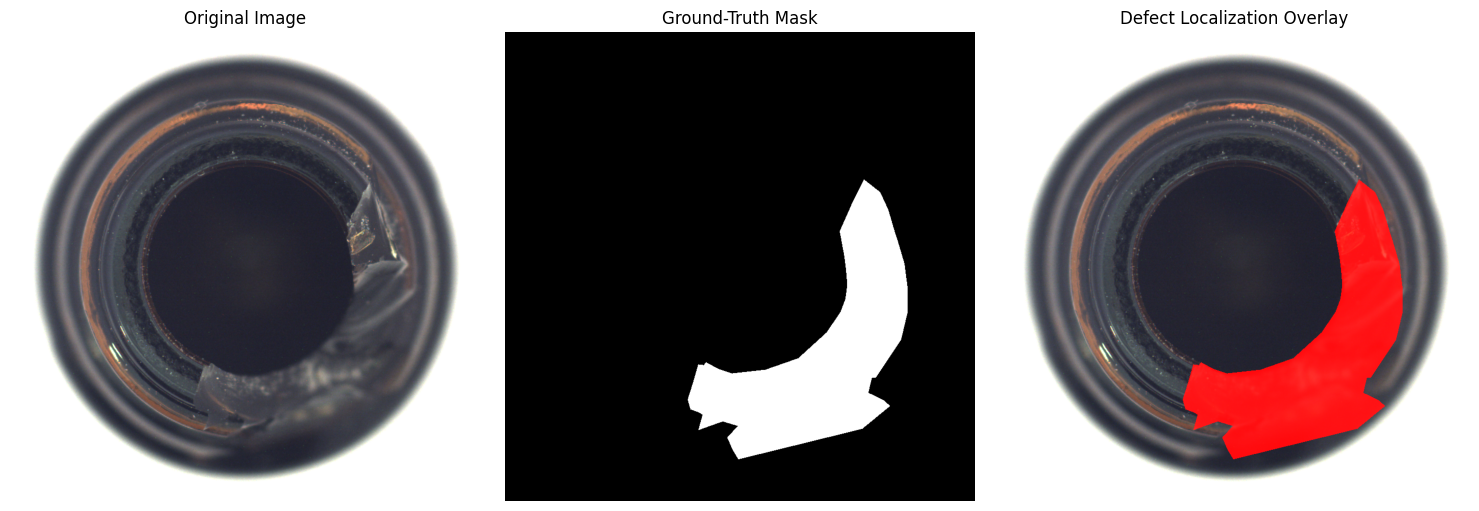

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Paths
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large/000.png"
mask_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/000_mask.png"

# Load image and mask
image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

# Convert to NumPy arrays
image_array = np.array(image)
mask_array = np.array(mask)

# Create a copy of the original image
overlay = image_array.copy()

# Highlight defect region
defect_pixels = mask_array > 0

# Increase red channel in defect area
overlay[defect_pixels, 0] = 255

# Reduce green and blue channels
overlay[defect_pixels, 1] = overlay[defect_pixels, 1] * 0.3
overlay[defect_pixels, 2] = overlay[defect_pixels, 2] * 0.3

# Display original, mask and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Defect Localization Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [17]:
import os
from PIL import Image

# Path to training images
train_good_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good"

# Get image files
image_files = [
    f for f in os.listdir(train_good_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Check dimensions of the first 10 images
print("Image dimensions:")

for file in image_files[:10]:
    image_path = os.path.join(train_good_path, file)
    image = Image.open(image_path)
    print(f"{file}: {image.size}")

Image dimensions:
000.png: (900, 900)
001.png: (900, 900)
002.png: (900, 900)
003.png: (900, 900)
004.png: (900, 900)
005.png: (900, 900)
006.png: (900, 900)
007.png: (900, 900)
008.png: (900, 900)
009.png: (900, 900)


In [18]:
from PIL import Image

image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (900, 900)
Image mode: RGB


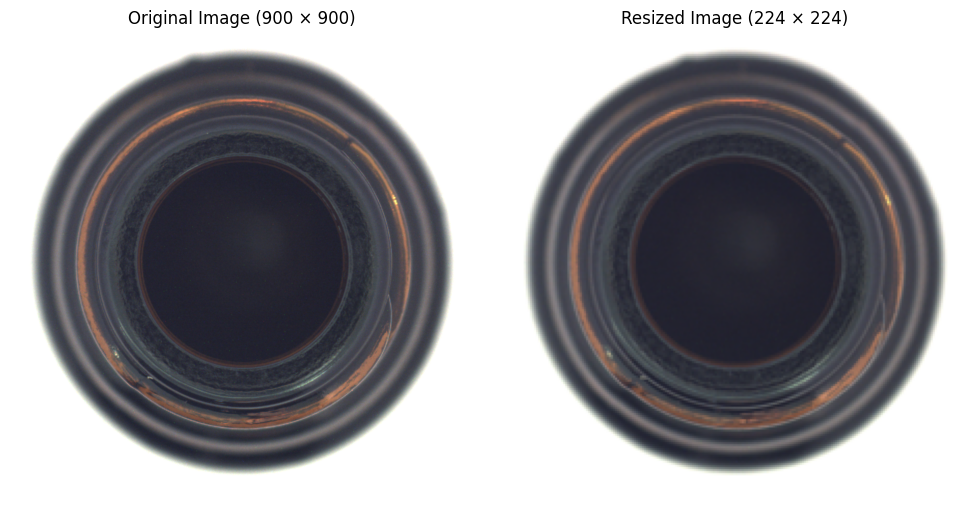

In [19]:
from PIL import Image
import matplotlib.pyplot as plt

# Original image
image_path = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/train/good/000.png"

# Load image
image = Image.open(image_path).convert("RGB")

# Resize
resized_image = image.resize((224, 224))

# Display original and resized images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image (900 × 900)")
axes[0].axis("off")

axes[1].imshow(resized_image)
axes[1].set_title("Resized Image (224 × 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [20]:
# Step 8: Load pretrained ResNet18

weights = models.ResNet18_Weights.DEFAULT

resnet = models.resnet18(weights=weights)

# Remove the final classification layer
feature_extractor = nn.Sequential(*list(resnet.children())[:-2])

# Move the feature extractor to CPU/GPU
feature_extractor = feature_extractor.to(device)

# Evaluation mode
feature_extractor.eval()

print("ResNet18 loaded successfully!")
print("Using device:", device)
print("Final classification layer removed.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s] 


ResNet18 loaded successfully!
Using device: cpu
Final classification layer removed.


In [21]:
# Step 9: Define image preprocessing for ResNet18

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing defined successfully!")

Image preprocessing defined successfully!


In [22]:
# Step 10: Load and verify one normal bottle image

# Get the first normal training image
image_name = train_images[0]
image_path = os.path.join(train_good_path, image_name)

# Open the original image
image = Image.open(image_path).convert("RGB")

# Apply the ResNet preprocessing
image_tensor = transform(image)

print("Image name:", image_name)
print("Original image size:", image.size)
print("Processed tensor shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)

Image name: 000.png
Original image size: (900, 900)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32


In [23]:
# Step 11: Extract a feature map from one normal bottle image

# Add batch dimension
input_tensor = image_tensor.unsqueeze(0).to(device)

# Extract features
with torch.no_grad():
    feature_map = feature_extractor(input_tensor)

print("Input shape:", input_tensor.shape)
print("Feature map shape:", feature_map.shape)

Input shape: torch.Size([1, 3, 224, 224])
Feature map shape: torch.Size([1, 512, 7, 7])


In [24]:
# Step 12: Convert the feature map into patch-level embeddings

# Remove the batch dimension
feature_map = feature_map.squeeze(0)

# Rearrange:
# [512, 7, 7] → [7, 7, 512] → [49, 512]
patch_embeddings = feature_map.permute(1, 2, 0).reshape(-1, 512)

print("Original feature map shape:", feature_map.shape)
print("Patch embeddings shape:", patch_embeddings.shape)

Original feature map shape: torch.Size([512, 7, 7])
Patch embeddings shape: torch.Size([49, 512])


In [25]:
# Step 13: Extract patch embeddings from all normal training images

normal_patch_features = []

for i, image_name in enumerate(train_images):

    image_path = os.path.join(train_good_path, image_name)

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess image
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Extract ResNet feature map
    with torch.no_grad():
        feature_map = feature_extractor(image_tensor)

    # Remove batch dimension
    feature_map = feature_map.squeeze(0)

    # Convert [512, 7, 7] → [49, 512]
    patches = feature_map.permute(1, 2, 0).reshape(-1, 512)

    # Store patch embeddings
    normal_patch_features.append(patches.cpu())

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(train_images)} images")

# Combine all patch embeddings
normal_patch_features = torch.cat(normal_patch_features, dim=0)

print("\nFeature extraction completed!")
print("Normal memory bank candidate shape:", normal_patch_features.shape)

Processed 25/209 images
Processed 50/209 images
Processed 75/209 images
Processed 100/209 images
Processed 125/209 images
Processed 150/209 images
Processed 175/209 images
Processed 200/209 images

Feature extraction completed!
Normal memory bank candidate shape: torch.Size([10241, 512])


In [26]:
# Step 14: Create a representative normal feature memory bank

memory_bank_size = 2000

# Make the selection reproducible
torch.manual_seed(42)

# Randomly select representative normal patch features
selected_indices = torch.randperm(
    normal_patch_features.shape[0]
)[:memory_bank_size]

memory_bank = normal_patch_features[selected_indices]

print("Original normal patch features:", normal_patch_features.shape)
print("Memory bank shape:", memory_bank.shape)
print("Memory bank size:", memory_bank.shape[0])

Original normal patch features: torch.Size([10241, 512])
Memory bank shape: torch.Size([2000, 512])
Memory bank size: 2000


In [27]:
# Step 15: Define nearest-neighbor anomaly scoring

def calculate_patch_anomaly_scores(patch_embeddings, memory_bank):
    """
    Calculate the nearest-neighbor distance for every test patch.

    patch_embeddings: [number_of_patches, 512]
    memory_bank:      [memory_bank_size, 512]

    Returns:
        nearest_distances: anomaly score for each patch
        nearest_indices:   index of the nearest normal patch
    """

    # Calculate Euclidean distance between every test patch
    # and every memory-bank patch
    distances = torch.cdist(
        patch_embeddings,
        memory_bank
    )

    # Find the closest normal patch for each test patch
    nearest_distances, nearest_indices = torch.min(
        distances,
        dim=1
    )

    return nearest_distances, nearest_indices


print("Nearest-neighbor anomaly scoring function defined!")

Nearest-neighbor anomaly scoring function defined!


In [28]:
# Step 16: Test anomaly scoring on one normal bottle image

# Use the first normal training image
image = Image.open(image_path).convert("RGB")

# Preprocess
input_tensor = transform(image).unsqueeze(0).to(device)

# Extract ResNet features
with torch.no_grad():
    feature_map = feature_extractor(input_tensor)

# Convert feature map to patch embeddings
feature_map = feature_map.squeeze(0)
patch_embeddings = feature_map.permute(1, 2, 0).reshape(-1, 512)

# Calculate nearest-neighbor distances
patch_scores, nearest_indices = calculate_patch_anomaly_scores(
    patch_embeddings,
    memory_bank
)

# Image-level anomaly score
image_anomaly_score = patch_scores.max().item()

print("Number of patches:", len(patch_scores))
print("Patch score shape:", patch_scores.shape)
print("Minimum patch score:", patch_scores.min().item())
print("Maximum patch score:", patch_scores.max().item())
print("Mean patch score:", patch_scores.mean().item())
print("Image anomaly score:", image_anomaly_score)

Number of patches: 49
Patch score shape: torch.Size([49])
Minimum patch score: 0.0
Maximum patch score: 12.122220993041992
Mean patch score: 5.475192546844482
Image anomaly score: 12.122220993041992


In [29]:
# Step 17: Calculate anomaly score for one unseen normal test image

# Path to test/good
test_good_path = os.path.join(test_path, "good")

# Get the first normal test image
test_good_images = [
    f for f in os.listdir(test_good_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

test_image_name = test_good_images[0]
test_image_path = os.path.join(test_good_path, test_image_name)

# Load and preprocess
test_image = Image.open(test_image_path).convert("RGB")
test_tensor = transform(test_image).unsqueeze(0).to(device)

# Extract ResNet feature map
with torch.no_grad():
    test_feature_map = feature_extractor(test_tensor)

# Convert feature map → 49 patch embeddings
test_feature_map = test_feature_map.squeeze(0)
test_patches = test_feature_map.permute(1, 2, 0).reshape(-1, 512)

# Calculate nearest-neighbor patch scores
test_patch_scores, _ = calculate_patch_anomaly_scores(
    test_patches,
    memory_bank
)

# Image-level anomaly score
test_image_score = test_patch_scores.max().item()

print("Test image:", test_image_name)
print("Number of patches:", len(test_patch_scores))
print("Minimum patch score:", test_patch_scores.min().item())
print("Maximum patch score:", test_patch_scores.max().item())
print("Mean patch score:", test_patch_scores.mean().item())
print("Image anomaly score:", test_image_score)

Test image: 000.png
Number of patches: 49
Minimum patch score: 0.8439489006996155
Maximum patch score: 12.340229034423828
Mean patch score: 6.8431596755981445
Image anomaly score: 12.340229034423828


In [30]:
# Step 18: Calculate anomaly score for one defective image

# Path to contamination test images
contamination_path = os.path.join(test_path, "contamination")

# Get the first contamination image
contamination_images = [
    f for f in os.listdir(contamination_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

defect_image_name = contamination_images[0]
defect_image_path = os.path.join(contamination_path, defect_image_name)

# Load and preprocess
defect_image = Image.open(defect_image_path).convert("RGB")
defect_tensor = transform(defect_image).unsqueeze(0).to(device)

# Extract ResNet feature map
with torch.no_grad():
    defect_feature_map = feature_extractor(defect_tensor)

# Convert feature map → 49 patch embeddings
defect_feature_map = defect_feature_map.squeeze(0)
defect_patches = defect_feature_map.permute(1, 2, 0).reshape(-1, 512)

# Calculate nearest-neighbor patch scores
defect_patch_scores, _ = calculate_patch_anomaly_scores(
    defect_patches,
    memory_bank
)

# Image-level anomaly score
defect_image_score = defect_patch_scores.max().item()

print("Defective image:", defect_image_name)
print("Defect category: contamination")
print("Number of patches:", len(defect_patch_scores))
print("Minimum patch score:", defect_patch_scores.min().item())
print("Maximum patch score:", defect_patch_scores.max().item())
print("Mean patch score:", defect_patch_scores.mean().item())
print("Image anomaly score:", defect_image_score)

Defective image: 000.png
Defect category: contamination
Number of patches: 49
Minimum patch score: 1.9066661596298218
Maximum patch score: 30.879941940307617
Mean patch score: 14.345587730407715
Image anomaly score: 30.879941940307617


In [31]:
# Step 19: Create a reusable function for image-level anomaly scoring

def get_anomaly_score(image_path, feature_extractor, memory_bank, transform, device):
    """
    Extract ResNet patch features from one image
    and calculate its nearest-neighbor anomaly score.
    """

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Extract feature map
    with torch.no_grad():
        feature_map = feature_extractor(image_tensor)

    # Convert [1, 512, 7, 7] → [49, 512]
    feature_map = feature_map.squeeze(0)
    patch_embeddings = feature_map.permute(1, 2, 0).reshape(-1, 512)

    # Calculate nearest-neighbor distances
    patch_scores, nearest_indices = calculate_patch_anomaly_scores(
        patch_embeddings,
        memory_bank
    )

    # Image-level anomaly score
    image_score = patch_scores.max().item()

    return image_score, patch_scores


print("Reusable anomaly scoring function created!")

Reusable anomaly scoring function created!


In [32]:
# Step 20: Calculate anomaly scores for all normal test images

normal_test_results = []

for image_name in test_good_images:

    image_path = os.path.join(test_good_path, image_name)

    score, patch_scores = get_anomaly_score(
        image_path,
        feature_extractor,
        memory_bank,
        transform,
        device
    )

    normal_test_results.append({
        "image": image_name,
        "category": "good",
        "label": 0,
        "anomaly_score": score
    })

print("Processed normal test images:", len(normal_test_results))

# Convert results to DataFrame
normal_test_df = pd.DataFrame(normal_test_results)

print("\nNormal test score statistics:")
print(normal_test_df["anomaly_score"].describe())

Processed normal test images: 20

Normal test score statistics:
count    20.000000
mean     12.384666
std       2.437626
min      10.579406
25%      11.028634
50%      11.789622
75%      12.420530
max      21.598894
Name: anomaly_score, dtype: float64


In [33]:
# Step 21: Calculate anomaly scores for all defective test images

defect_categories = [
    "contamination",
    "broken_large",
    "broken_small"
]

defect_test_results = []

for category in defect_categories:

    category_path = os.path.join(test_path, category)

    category_images = [
        f for f in os.listdir(category_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"Processing {category}: {len(category_images)} images")

    for image_name in category_images:

        image_path = os.path.join(category_path, image_name)

        score, patch_scores = get_anomaly_score(
            image_path,
            feature_extractor,
            memory_bank,
            transform,
            device
        )

        defect_test_results.append({
            "image": image_name,
            "category": category,
            "label": 1,
            "anomaly_score": score
        })

print("\nTotal defective images processed:", len(defect_test_results))

# Convert results to DataFrame
defect_test_df = pd.DataFrame(defect_test_results)

print("\nDefective test score statistics:")
print(defect_test_df["anomaly_score"].describe())

Processing contamination: 21 images
Processing broken_large: 20 images
Processing broken_small: 22 images

Total defective images processed: 63

Defective test score statistics:
count    63.000000
mean     29.850517
std       8.347603
min      13.630428
25%      23.852324
50%      30.314602
75%      33.799408
max      53.798161
Name: anomaly_score, dtype: float64


In [34]:
# Step 22: Combine normal and defective test results

all_test_results = pd.concat(
    [normal_test_df, defect_test_df],
    ignore_index=True
)

print("Total test images:", len(all_test_results))

print("\nClass distribution:")
print(all_test_results["label"].value_counts())

print("\nResults preview:")
display(all_test_results.head())

Total test images: 83

Class distribution:
label
1    63
0    20
Name: count, dtype: int64

Results preview:


,image,category,label,anomaly_score
0,000.png,good,0,12.340229
1,001.png,good,0,10.789309
2,002.png,good,0,13.065826
3,003.png,good,0,11.013486
4,004.png,good,0,11.823593


In [35]:
# Step 23: Evaluate anomaly scores using ROC-AUC and PR-AUC

from sklearn.metrics import roc_auc_score, average_precision_score

y_true = all_test_results["label"].values
y_scores = all_test_results["anomaly_score"].values

# ROC-AUC
roc_auc = roc_auc_score(y_true, y_scores)

# PR-AUC (Average Precision)
pr_auc = average_precision_score(y_true, y_scores)

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC :", round(pr_auc, 4))

ROC-AUC: 0.9921
PR-AUC : 0.9974


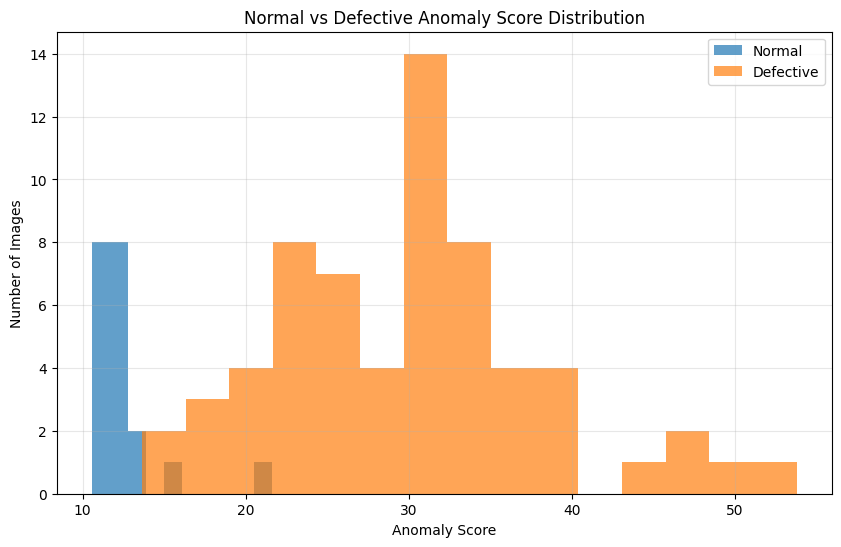

In [36]:
# Step 24: Visualize normal vs defective anomaly scores

plt.figure(figsize=(10, 6))

plt.hist(
    normal_test_df["anomaly_score"],
    bins=10,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    defect_test_df["anomaly_score"],
    bins=15,
    alpha=0.7,
    label="Defective"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Images")
plt.title("Normal vs Defective Anomaly Score Distribution")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Candidate threshold: 15.2486
True Positive Rate (Recall): 0.9841
False Positive Rate: 0.05
Youden's J: 0.9341


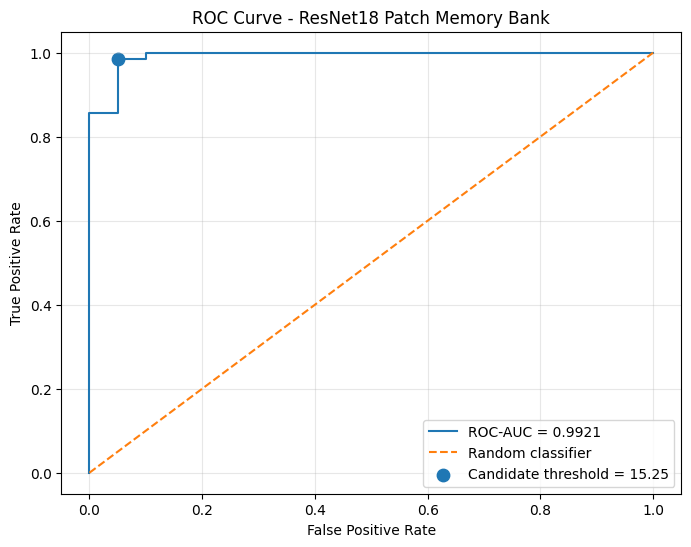

In [37]:
# Step 25: Analyze ROC curve and candidate decision threshold

from sklearn.metrics import roc_curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_scores
)

# Youden's J statistic
youden_j = tpr - fpr

# Find the threshold with the highest Youden's J
best_index = np.argmax(youden_j)
candidate_threshold = thresholds[best_index]

print("Candidate threshold:", round(candidate_threshold, 4))
print("True Positive Rate (Recall):", round(tpr[best_index], 4))
print("False Positive Rate:", round(fpr[best_index], 4))
print("Youden's J:", round(youden_j[best_index], 4))

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.scatter(
    fpr[best_index],
    tpr[best_index],
    s=80,
    label=f"Candidate threshold = {candidate_threshold:.2f}"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ResNet18 Patch Memory Bank")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [38]:
# Step 26: Evaluate classification performance at the candidate threshold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Convert anomaly scores into predictions
# Higher score = defective
y_pred = (y_scores >= candidate_threshold).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Classification Performance")
print("--------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Defective"]
))

Classification Performance
--------------------------
Accuracy : 0.9759
Precision: 0.9841
Recall   : 0.9841
F1-Score : 0.9841

Confusion Matrix:
[[19  1]
 [ 1 62]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95        20
   Defective       0.98      0.98      0.98        63

    accuracy                           0.98        83
   macro avg       0.97      0.97      0.97        83
weighted avg       0.98      0.98      0.98        83



In [39]:
# Step 27: Inspect one MVTec ground-truth defect mask

# Ground-truth folder for contamination
contamination_gt_path = os.path.join(
    ground_truth_path,
    "contamination"
)

# Get available ground-truth mask files
gt_files = [
    f for f in os.listdir(contamination_gt_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Ground-truth files found:", len(gt_files))
print("First few files:", gt_files[:5])

# Load the mask corresponding to 000.png
gt_mask_path = os.path.join(contamination_gt_path, "000_mask.png")

gt_mask = Image.open(gt_mask_path).convert("L")

print("\nGround-truth mask path:", gt_mask_path)
print("Ground-truth mask size:", gt_mask.size)

# Check mask values
gt_array = np.array(gt_mask)

print("Unique pixel values:", np.unique(gt_array))
print("Maximum pixel value:", gt_array.max())

Ground-truth files found: 21
First few files: ['000_mask.png', '001_mask.png', '002_mask.png', '003_mask.png', '004_mask.png']

Ground-truth mask path: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/contamination/000_mask.png
Ground-truth mask size: (900, 900)
Unique pixel values: [  0 255]
Maximum pixel value: 255


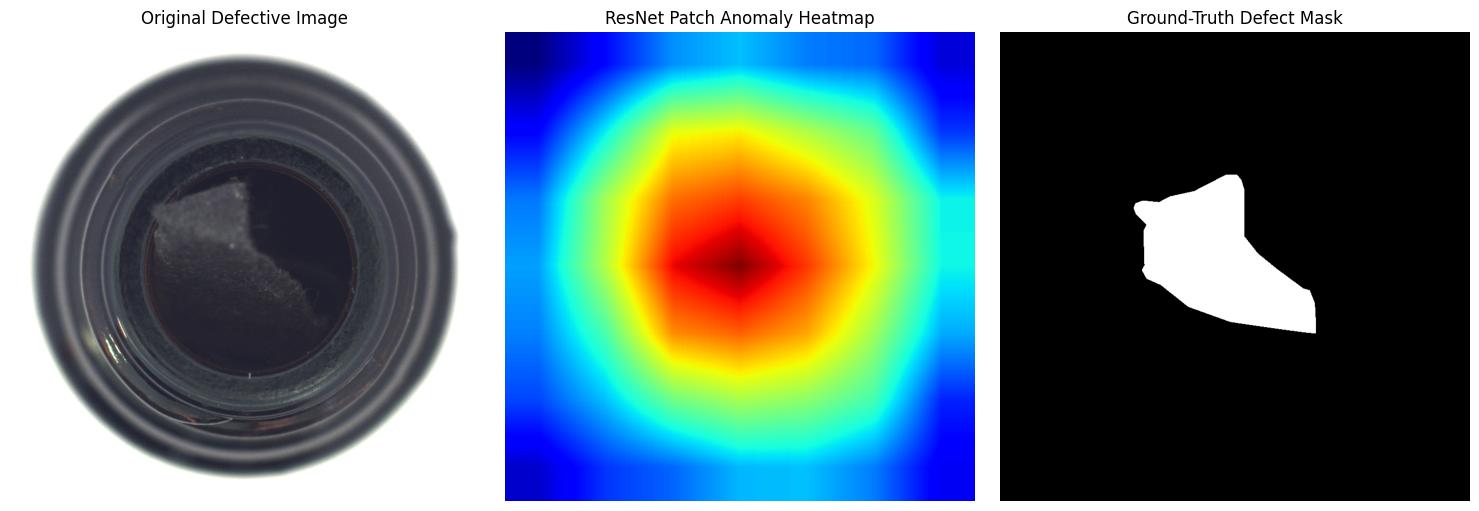

Image anomaly score: 30.8799
Anomaly map shape: (900, 900)


In [40]:
# Step 28: Generate and visualize the anomaly heatmap

# Use the contamination image we tested earlier
visual_image_path = defect_image_path

# Get patch-level anomaly scores
visual_score, visual_patch_scores = get_anomaly_score(
    visual_image_path,
    feature_extractor,
    memory_bank,
    transform,
    device
)

# Convert 49 patch scores → 7 × 7 anomaly map
anomaly_map_7x7 = visual_patch_scores.reshape(7, 7).cpu().numpy()

# Normalize anomaly map for visualization
anomaly_map_normalized = (
    anomaly_map_7x7 - anomaly_map_7x7.min()
) / (
    anomaly_map_7x7.max() - anomaly_map_7x7.min() + 1e-8
)

# Resize 7 × 7 map → 900 × 900
anomaly_map_image = Image.fromarray(
    (anomaly_map_normalized * 255).astype(np.uint8)
)

anomaly_map_resized = anomaly_map_image.resize(
    (900, 900),
    Image.Resampling.BILINEAR
)

anomaly_map_array = np.array(anomaly_map_resized) / 255.0

# Load original image and ground-truth mask
original_image = Image.open(visual_image_path).convert("RGB")
ground_truth = np.array(gt_mask) / 255.0

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Defective Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(anomaly_map_array, cmap="jet")
plt.title("ResNet Patch Anomaly Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground-Truth Defect Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image anomaly score:", round(visual_score, 4))
print("Anomaly map shape:", anomaly_map_array.shape)

In [41]:
# Step 29: Create a multi-layer ResNet18 feature extractor
# We will use Layer 2 + Layer 3 for better spatial localization.

class ResNetFeatureExtractor(nn.Module):
    def __init__(self, resnet):
        super().__init__()

        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool

        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)

        # Layer 2: [batch, 128, 28, 28]
        layer2_features = self.layer2(x)

        # Layer 3: [batch, 256, 14, 14]
        layer3_features = self.layer3(layer2_features)

        # Upsample Layer 3 to 28 × 28
        layer3_features = torch.nn.functional.interpolate(
            layer3_features,
            size=layer2_features.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Combine Layer 2 + Layer 3
        combined_features = torch.cat(
            [layer2_features, layer3_features],
            dim=1
        )

        return combined_features


# Create the new feature extractor
feature_extractor = ResNetFeatureExtractor(resnet).to(device)
feature_extractor.eval()

print("Multi-layer ResNet18 feature extractor created!")

Multi-layer ResNet18 feature extractor created!


In [42]:
# Step 30: Verify the multi-layer feature map

# Use one normal training image
test_feature_image = Image.open(image_path).convert("RGB")

test_feature_tensor = transform(test_feature_image).unsqueeze(0).to(device)

# Extract multi-layer features
with torch.no_grad():
    multi_layer_features = feature_extractor(test_feature_tensor)

print("Input shape:", test_feature_tensor.shape)
print("Multi-layer feature map shape:", multi_layer_features.shape)

Input shape: torch.Size([1, 3, 224, 224])
Multi-layer feature map shape: torch.Size([1, 384, 28, 28])


In [43]:
# Step 31: Convert multi-layer feature map into patch embeddings

multi_layer_features = multi_layer_features.squeeze(0)

patch_embeddings_new = (
    multi_layer_features
    .permute(1, 2, 0)
    .reshape(-1, 384)
)

print("Feature map shape:", multi_layer_features.shape)
print("Patch embeddings shape:", patch_embeddings_new.shape)

Feature map shape: torch.Size([384, 28, 28])
Patch embeddings shape: torch.Size([784, 384])


In [44]:
# Step 32: Extract normalized patch features from all normal training images

normal_patch_features_new = []

for i, image_name in enumerate(train_images):

    image_path_current = os.path.join(train_good_path, image_name)

    # Load and preprocess image
    image_current = Image.open(image_path_current).convert("RGB")
    image_tensor_current = transform(image_current).unsqueeze(0).to(device)

    # Extract multi-layer ResNet features
    with torch.no_grad():
        feature_map_current = feature_extractor(image_tensor_current)

    # [1, 384, 28, 28] → [784, 384]
    feature_map_current = feature_map_current.squeeze(0)

    patches_current = (
        feature_map_current
        .permute(1, 2, 0)
        .reshape(-1, 384)
    )

    # L2-normalize each patch embedding
    patches_current = torch.nn.functional.normalize(
        patches_current,
        p=2,
        dim=1
    )

    # Store on CPU
    normal_patch_features_new.append(
        patches_current.cpu()
    )

    if (i + 1) % 25 == 0:
        print(f"Processed {i + 1}/{len(train_images)} images")

# Combine all normal patch embeddings
normal_patch_features_new = torch.cat(
    normal_patch_features_new,
    dim=0
)

print("\nFeature extraction completed!")
print("Normal patch feature collection shape:",
      normal_patch_features_new.shape)

Processed 25/209 images
Processed 50/209 images
Processed 75/209 images
Processed 100/209 images
Processed 125/209 images
Processed 150/209 images
Processed 175/209 images
Processed 200/209 images

Feature extraction completed!
Normal patch feature collection shape: torch.Size([163856, 384])


In [45]:
# Step 33: Build the new normal patch memory bank

memory_bank_size_new = 5000

# Make selection reproducible
torch.manual_seed(42)

# Randomly select normal patch embeddings
selected_indices_new = torch.randperm(
    normal_patch_features_new.shape[0]
)[:memory_bank_size_new]

memory_bank_new = normal_patch_features_new[selected_indices_new]

print("Original normal patch features:",
      normal_patch_features_new.shape)

print("New memory bank shape:",
      memory_bank_new.shape)

print("Memory bank size:",
      memory_bank_new.shape[0])

Original normal patch features: torch.Size([163856, 384])
New memory bank shape: torch.Size([5000, 384])
Memory bank size: 5000


In [46]:
# Step 34: Define anomaly scoring for the new multi-layer features

def get_patch_anomaly_scores_new(image_path, feature_extractor, memory_bank, transform, device):
    """
    Extract multi-layer ResNet patch features and compare
    them with the normal patch memory bank.
    """

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Extract multi-layer features
    with torch.no_grad():
        feature_map = feature_extractor(image_tensor)

    # [1, 384, 28, 28] -> [784, 384]
    feature_map = feature_map.squeeze(0)

    patch_embeddings = (
        feature_map
        .permute(1, 2, 0)
        .reshape(-1, 384)
    )

    # L2 normalize patch embeddings
    patch_embeddings = torch.nn.functional.normalize(
        patch_embeddings,
        p=2,
        dim=1
    )

    # Nearest-neighbor distances
    distances = torch.cdist(
        patch_embeddings.cpu(),
        memory_bank
    )

    # Closest normal patch for every test patch
    nearest_distances, nearest_indices = torch.min(
        distances,
        dim=1
    )

    # Image-level anomaly score
    image_score = nearest_distances.max().item()

    return image_score, nearest_distances


print("New PatchCore-style anomaly scoring function created!")

New PatchCore-style anomaly scoring function created!


In [47]:
defect_image_path = os.path.join(
    test_path,
    "contamination",
    "000.png"
)

defect_score, defect_patch_scores = get_patch_anomaly_scores_new(
    defect_image_path,
    feature_extractor,
    memory_bank_new,
    transform,
    device
)

print("Defective image:", defect_image_path)
print("Image anomaly score:", defect_score)
print("Number of patch scores:", len(defect_patch_scores))
print("Patch score shape:", defect_patch_scores.shape)
print("Minimum patch score:", defect_patch_scores.min().item())
print("Maximum patch score:", defect_patch_scores.max().item())
print("Mean patch score:", defect_patch_scores.mean().item())

Defective image: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/contamination/000.png
Image anomaly score: 0.9005994200706482
Number of patch scores: 784
Patch score shape: torch.Size([784])
Minimum patch score: 0.005545808933675289
Maximum patch score: 0.9005994200706482
Mean patch score: 0.3143937587738037


In [48]:
normal_image_path = os.path.join(
    test_path,
    "good",
    "000.png"
)

normal_score, normal_patch_scores = get_patch_anomaly_scores_new(
    normal_image_path,
    feature_extractor,
    memory_bank_new,
    transform,
    device
)

print("Normal image:", normal_image_path)
print("Image anomaly score:", normal_score)
print("Number of patch scores:", len(normal_patch_scores))
print("Patch score shape:", normal_patch_scores.shape)
print("Minimum patch score:", normal_patch_scores.min().item())
print("Maximum patch score:", normal_patch_scores.max().item())
print("Mean patch score:", normal_patch_scores.mean().item())

Normal image: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/good/000.png
Image anomaly score: 0.5615696310997009
Number of patch scores: 784
Patch score shape: torch.Size([784])
Minimum patch score: 0.0083151301369071
Maximum patch score: 0.5615696310997009
Mean patch score: 0.22373506426811218


In [49]:
from sklearn.metrics import roc_auc_score, average_precision_score

test_scores_new = []
test_labels_new = []
test_names_new = []

# Normal test images
for image_name in test_good_images:
    image_path_current = os.path.join(
        test_good_path,
        image_name
    )

    score_current, _ = get_patch_anomaly_scores_new(
        image_path_current,
        feature_extractor,
        memory_bank_new,
        transform,
        device
    )

    test_scores_new.append(score_current)
    test_labels_new.append(0)
    test_names_new.append(f"good/{image_name}")

# Defective test images
defect_categories = [
    "contamination",
    "broken_large",
    "broken_small"
]

for category in defect_categories:

    category_path = os.path.join(test_path, category)

    category_images = sorted([
        f for f in os.listdir(category_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    print(f"Processing {category}: {len(category_images)} images")

    for image_name in category_images:
        image_path_current = os.path.join(
            category_path,
            image_name
        )

        score_current, _ = get_patch_anomaly_scores_new(
            image_path_current,
            feature_extractor,
            memory_bank_new,
            transform,
            device
        )

        test_scores_new.append(score_current)
        test_labels_new.append(1)
        test_names_new.append(f"{category}/{image_name}")

print("\nFinished scoring all test images.")

test_scores_new = np.array(test_scores_new)
test_labels_new = np.array(test_labels_new)

roc_auc_new = roc_auc_score(
    test_labels_new,
    test_scores_new
)

pr_auc_new = average_precision_score(
    test_labels_new,
    test_scores_new
)

print("Total test images:", len(test_scores_new))
print("Normal images:", np.sum(test_labels_new == 0))
print("Defective images:", np.sum(test_labels_new == 1))
print("New ROC-AUC:", roc_auc_new)
print("New PR-AUC:", pr_auc_new)

Processing contamination: 21 images
Processing broken_large: 20 images
Processing broken_small: 22 images

Finished scoring all test images.
Total test images: 83
Normal images: 20
Defective images: 63
New ROC-AUC: 0.9992063492063492
New PR-AUC: 0.999751984126984


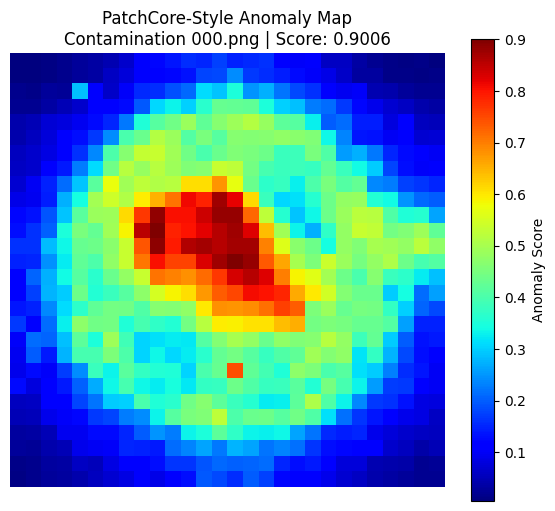

In [50]:
# Get the 784 patch anomaly scores again for the contamination image
contamination_path = os.path.join(
    test_path,
    "contamination",
    "000.png"
)

contamination_score, contamination_patch_scores = get_patch_anomaly_scores_new(
    contamination_path,
    feature_extractor,
    memory_bank_new,
    transform,
    device
)

# Convert 784 scores into a 28 x 28 anomaly map
anomaly_map = contamination_patch_scores.reshape(28, 28).numpy()

# Display the anomaly map
plt.figure(figsize=(7, 6))
plt.imshow(anomaly_map, cmap="jet")
plt.colorbar(label="Anomaly Score")
plt.title(
    f"PatchCore-Style Anomaly Map\n"
    f"Contamination 000.png | Score: {contamination_score:.4f}"
)
plt.axis("off")
plt.show()

Ground-truth mask size: (900, 900)
Unique pixel values: [  0 255]


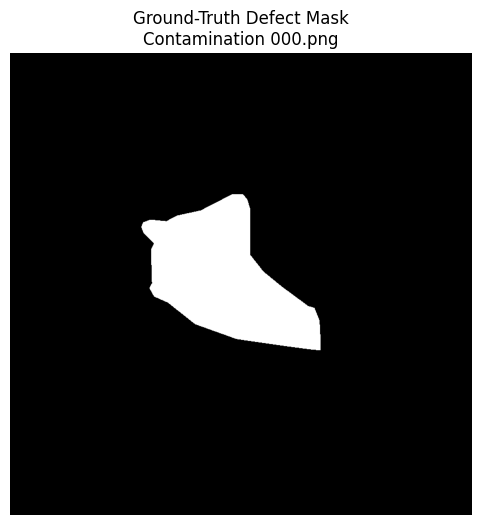

In [51]:
# Load the ground-truth mask for contamination/000.png
ground_truth_mask_path = os.path.join(
    ground_truth_path,
    "contamination",
    "000_mask.png"
)

ground_truth_mask = Image.open(
    ground_truth_mask_path
).convert("L")

print("Ground-truth mask size:", ground_truth_mask.size)
print("Unique pixel values:", np.unique(np.array(ground_truth_mask)))

plt.figure(figsize=(7, 6))
plt.imshow(ground_truth_mask, cmap="gray")
plt.title("Ground-Truth Defect Mask\nContamination 000.png")
plt.axis("off")
plt.show()

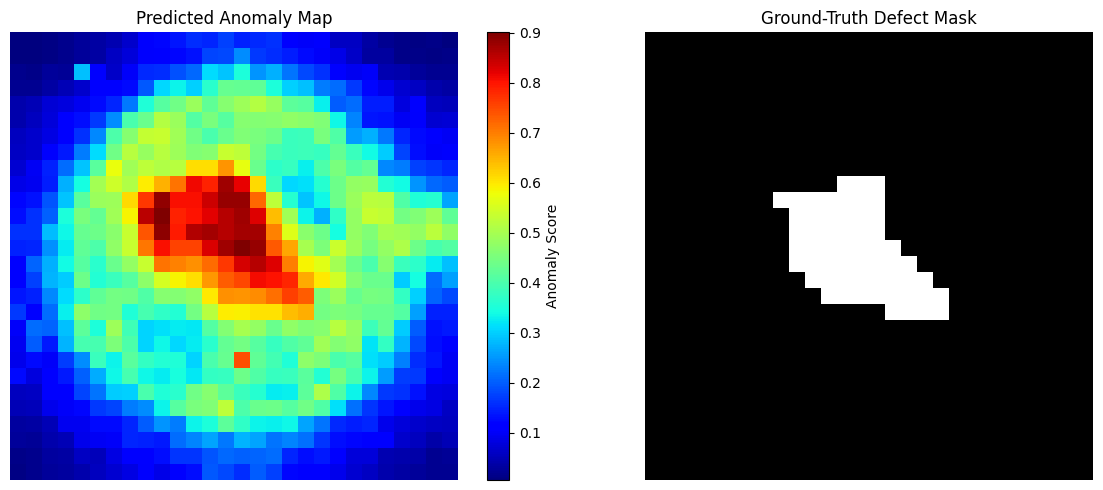

Anomaly map shape: (28, 28)
Ground-truth shape: (28, 28)
Ground-truth defect pixels: 57


In [52]:
# Convert ground-truth mask to the same 28x28 resolution
ground_truth_mask_28 = ground_truth_mask.resize(
    (28, 28),
    Image.Resampling.NEAREST
)

ground_truth_array_28 = np.array(
    ground_truth_mask_28
)

# Convert mask to binary: 1 = defect, 0 = normal
ground_truth_binary_28 = (
    ground_truth_array_28 > 0
).astype(np.uint8)

# Display anomaly map and ground truth side-by-side
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(anomaly_map, cmap="jet")
plt.colorbar(label="Anomaly Score")
plt.title("Predicted Anomaly Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ground_truth_binary_28, cmap="gray")
plt.title("Ground-Truth Defect Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Anomaly map shape:", anomaly_map.shape)
print("Ground-truth shape:", ground_truth_binary_28.shape)
print("Ground-truth defect pixels:", ground_truth_binary_28.sum())

In [53]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Flatten the anomaly map and ground-truth mask
anomaly_values = anomaly_map.flatten()
ground_truth_values = ground_truth_binary_28.flatten()

# Pixel-level AUROC
pixel_auroc = roc_auc_score(
    ground_truth_values,
    anomaly_values
)

# Pixel-level Average Precision
pixel_ap = average_precision_score(
    ground_truth_values,
    anomaly_values
)

print("Pixel-level Localization Results")
print("--------------------------------")
print("Pixel AUROC:", pixel_auroc)
print("Pixel AP:", pixel_ap)
print("Total pixels:", len(ground_truth_values))
print("Defect pixels:", ground_truth_values.sum())
print("Normal pixels:", (ground_truth_values == 0).sum())

Pixel-level Localization Results
--------------------------------
Pixel AUROC: 0.9895267742947464
Pixel AP: 0.8680761233996718
Total pixels: 784
Defect pixels: 57
Normal pixels: 727


In [54]:
pixel_aurocs = []
pixel_aps = []

for category in defect_categories:

    category_path = os.path.join(test_path, category)

    category_images = sorted([
        f for f in os.listdir(category_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    print(f"Evaluating localization: {category}")

    for image_name in category_images:

        # Image path
        image_path_current = os.path.join(
            category_path,
            image_name
        )

        # Ground-truth mask path
        mask_name = os.path.splitext(image_name)[0] + "_mask.png"

        mask_path_current = os.path.join(
            ground_truth_path,
            category,
            mask_name
        )

        # Get anomaly scores
        _, patch_scores_current = get_patch_anomaly_scores_new(
            image_path_current,
            feature_extractor,
            memory_bank_new,
            transform,
            device
        )

        # Convert patch scores to 28x28 anomaly map
        anomaly_map_current = (
            patch_scores_current
            .reshape(28, 28)
            .numpy()
        )

        # Load and resize ground-truth mask
        mask_current = Image.open(
            mask_path_current
        ).convert("L")

        mask_current = mask_current.resize(
            (28, 28),
            Image.Resampling.NEAREST
        )

        mask_array_current = np.array(mask_current)

        # Binary ground truth
        ground_truth_current = (
            mask_array_current > 0
        ).astype(np.uint8)

        # Flatten
        anomaly_values_current = (
            anomaly_map_current.flatten()
        )

        ground_truth_values_current = (
            ground_truth_current.flatten()
        )

        # Calculate metrics
        auroc_current = roc_auc_score(
            ground_truth_values_current,
            anomaly_values_current
        )

        ap_current = average_precision_score(
            ground_truth_values_current,
            anomaly_values_current
        )

        pixel_aurocs.append(auroc_current)
        pixel_aps.append(ap_current)

print("\nAll defective images evaluated!")

print("Number of defective images:", len(pixel_aurocs))
print("Mean Pixel AUROC:", np.mean(pixel_aurocs))
print("Mean Pixel AP:", np.mean(pixel_aps))
print("Minimum Pixel AUROC:", np.min(pixel_aurocs))
print("Maximum Pixel AUROC:", np.max(pixel_aurocs))
print("Minimum Pixel AP:", np.min(pixel_aps))
print("Maximum Pixel AP:", np.max(pixel_aps))

Evaluating localization: contamination
Evaluating localization: broken_large
Evaluating localization: broken_small

All defective images evaluated!
Number of defective images: 63
Mean Pixel AUROC: 0.9836335518872777
Mean Pixel AP: 0.7902690127408066
Minimum Pixel AUROC: 0.871632573670049
Maximum Pixel AUROC: 0.9991463935125907
Minimum Pixel AP: 0.38055555555555554
Maximum Pixel AP: 0.9736410943803184


In [55]:
from sklearn.metrics import (
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    test_labels_new,
    test_scores_new
)

# Youden's J statistic
youden_j = tpr - fpr

best_index = np.argmax(youden_j)

best_threshold = thresholds[best_index]

print("Candidate image-level threshold:", best_threshold)
print("True Positive Rate:", tpr[best_index])
print("False Positive Rate:", fpr[best_index])
print("Youden's J:", youden_j[best_index])

Candidate image-level threshold: 0.7095046639442444
True Positive Rate: 0.9841269841269841
False Positive Rate: 0.0
Youden's J: 0.9841269841269841


In [56]:
# Convert anomaly scores into predictions
predicted_labels_new = (
    test_scores_new >= best_threshold
).astype(int)

# Calculate final metrics
accuracy_new = accuracy_score(
    test_labels_new,
    predicted_labels_new
)

precision_new = precision_score(
    test_labels_new,
    predicted_labels_new
)

recall_new = recall_score(
    test_labels_new,
    predicted_labels_new
)

f1_new = f1_score(
    test_labels_new,
    predicted_labels_new
)

cm_new = confusion_matrix(
    test_labels_new,
    predicted_labels_new
)

print("FINAL IMAGE-LEVEL RESULTS")
print("=========================")
print("Threshold :", best_threshold)
print("Accuracy  :", accuracy_new)
print("Precision :", precision_new)
print("Recall    :", recall_new)
print("F1-Score  :", f1_new)
print("ROC-AUC   :", roc_auc_new)
print("PR-AUC    :", pr_auc_new)

print("\nConfusion Matrix:")
print(cm_new)

print("\nClassification Report:")
print(
    classification_report(
        test_labels_new,
        predicted_labels_new,
        target_names=["Normal", "Defective"]
    )
)

FINAL IMAGE-LEVEL RESULTS
Threshold : 0.7095046639442444
Accuracy  : 0.9879518072289156
Precision : 1.0
Recall    : 0.9841269841269841
F1-Score  : 0.992
ROC-AUC   : 0.9992063492063492
PR-AUC    : 0.999751984126984

Confusion Matrix:
[[20  0]
 [ 1 62]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      1.00      0.98        20
   Defective       1.00      0.98      0.99        63

    accuracy                           0.99        83
   macro avg       0.98      0.99      0.98        83
weighted avg       0.99      0.99      0.99        83



In [57]:
import os
import torch

model_save_dir = "/kaggle/working/defect_detection_model"
os.makedirs(model_save_dir, exist_ok=True)

# Save the ResNet feature extractor
torch.save(
    feature_extractor.state_dict(),
    os.path.join(model_save_dir, "resnet_feature_extractor.pth")
)

# Save the normal patch memory bank
torch.save(
    memory_bank_new,
    os.path.join(model_save_dir, "memory_bank.pth")
)

# Save the image-level threshold
torch.save(
    best_threshold,
    os.path.join(model_save_dir, "anomaly_threshold.pth")
)

print("Model components saved successfully!")
print("\nSaved files:")

for file_name in os.listdir(model_save_dir):
    file_path = os.path.join(model_save_dir, file_name)
    file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
    print(f"- {file_name}: {file_size_mb:.2f} MB")

Model components saved successfully!

Saved files:
- resnet_feature_extractor.pth: 10.66 MB
- memory_bank.pth: 7.33 MB
- anomaly_threshold.pth: 0.00 MB


In [58]:
def predict_defect(
    image_path,
    feature_extractor,
    memory_bank,
    transform,
    threshold,
    device
):
    """
    Predict whether a bottle image is normal or defective.
    """

    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        feature_map = feature_extractor(image_tensor)

    feature_map = feature_map.squeeze(0)

    # Convert feature map to patch embeddings
    patch_embeddings = (
        feature_map
        .permute(1, 2, 0)
        .reshape(-1, 384)
    )

    # L2 normalize patch features
    patch_embeddings = torch.nn.functional.normalize(
        patch_embeddings,
        p=2,
        dim=1
    )

    # Compare with normal memory bank
    distances = torch.cdist(
        patch_embeddings.cpu(),
        memory_bank
    )

    nearest_distances, _ = torch.min(
        distances,
        dim=1
    )

    # Image-level anomaly score
    anomaly_score = nearest_distances.max().item()

    # Classification
    if anomaly_score >= threshold:
        prediction = "Defective"
    else:
        prediction = "Normal"

    # Create anomaly map
    anomaly_map = (
        nearest_distances
        .reshape(28, 28)
        .numpy()
    )

    return prediction, anomaly_score, anomaly_map


print("Inference function created successfully!")

Inference function created successfully!


In [59]:
normal_test_path = os.path.join(
    test_path,
    "good",
    "000.png"
)

prediction, anomaly_score, anomaly_map_test = predict_defect(
    normal_test_path,
    feature_extractor,
    memory_bank_new,
    transform,
    best_threshold,
    device
)

print("Image:", normal_test_path)
print("Prediction:", prediction)
print("Anomaly Score:", anomaly_score)
print("Threshold:", best_threshold)
print("Anomaly Map Shape:", anomaly_map_test.shape)

Image: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/good/000.png
Prediction: Normal
Anomaly Score: 0.5615696310997009
Threshold: 0.7095046639442444
Anomaly Map Shape: (28, 28)


In [60]:
defective_test_path = os.path.join(
    test_path,
    "contamination",
    "000.png"
)

prediction, anomaly_score, anomaly_map_test = predict_defect(
    defective_test_path,
    feature_extractor,
    memory_bank_new,
    transform,
    best_threshold,
    device
)

print("Image:", defective_test_path)
print("Prediction:", prediction)
print("Anomaly Score:", anomaly_score)
print("Threshold:", best_threshold)
print("Anomaly Map Shape:", anomaly_map_test.shape)

Image: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/contamination/000.png
Prediction: Defective
Anomaly Score: 0.9005994200706482
Threshold: 0.7095046639442444
Anomaly Map Shape: (28, 28)


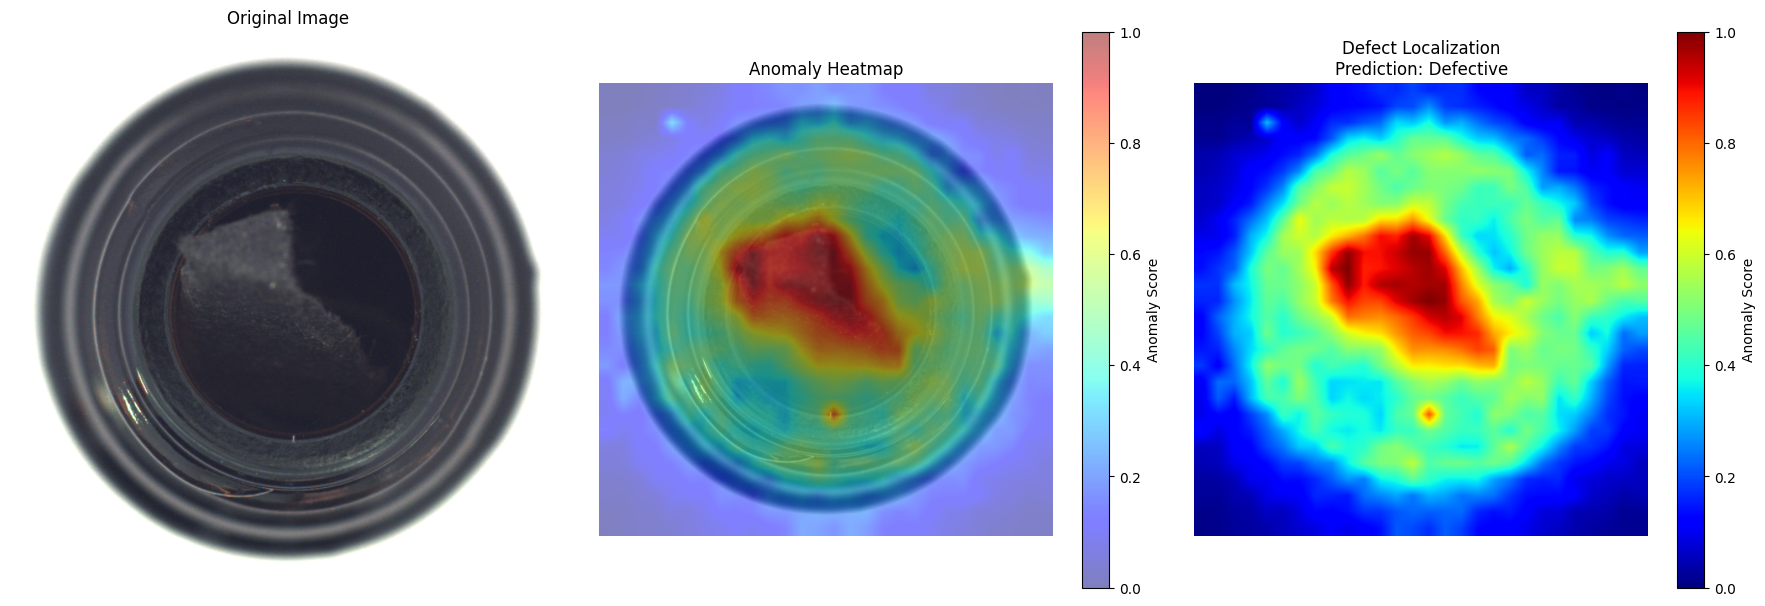

In [61]:
# Load the defective test image
image_original = Image.open(
    defective_test_path
).convert("RGB")

# Convert anomaly map to 900x900 for visualization
anomaly_map_resized = np.array(
    Image.fromarray(
        anomaly_map_test.astype(np.float32),
        mode="F"
    ).resize(
        image_original.size,
        Image.Resampling.BILINEAR
    )
)

# Normalize anomaly map for visualization
anomaly_map_normalized = (
    anomaly_map_resized - anomaly_map_resized.min()
) / (
    anomaly_map_resized.max() -
    anomaly_map_resized.min() + 1e-8
)

# Create figure
plt.figure(figsize=(18, 6))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(image_original)
plt.title("Original Image")
plt.axis("off")

# Anomaly heatmap
plt.subplot(1, 3, 2)
plt.imshow(image_original)
plt.imshow(
    anomaly_map_normalized,
    cmap="jet",
    alpha=0.5
)
plt.colorbar(label="Anomaly Score")
plt.title("Anomaly Heatmap")
plt.axis("off")

# Defect-highlighted image
plt.subplot(1, 3, 3)
plt.imshow(anomaly_map_normalized, cmap="jet")
plt.colorbar(label="Anomaly Score")
plt.title(
    f"Defect Localization\n"
    f"Prediction: {prediction}"
)
plt.axis("off")

plt.tight_layout()
plt.show()